In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Colormap, ListedColormap
import seaborn as sns

In [2]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split

X, y = make_classification(
    n_samples=200, n_features=2,
    n_informative=2, n_redundant=0,
    random_state=42
)


data = pd.DataFrame(np.hstack((X, y.reshape(-1, 1))),
                    columns=['x1', 'x2', 'y'])

__Задание 1.__

Обучите решающее дерево с параметрами по умолчанию, предварительно разбив выборку на обучающую и тестовую. Постройте разделяющую поверхность на трейне (для этого воспользуйтесь функцией `plot_surface`, пример ниже). Посчитайте accuracy на обучающей и тестовой выборках. Сильно ли деревья переобучились? (2б)

In [3]:
def plot_surface(clf, X, y):
    plot_step = 0.01
    palette = sns.color_palette(n_colors=len(np.unique(y)))
    cmap = ListedColormap(palette)
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, plot_step),
                         np.arange(y_min, y_max, plot_step))
    plt.tight_layout(h_pad=0.5, w_pad=0.5, pad=2.5)

    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    cs = plt.contourf(xx, yy, Z, cmap=cmap, alpha=0.3)

    plt.scatter(X[:, 0], X[:, 1], c=y, cmap=cmap, alpha=.7,
                edgecolors=np.array(palette)[y], linewidths=2)

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42)

In [5]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

### Your code is here

tree = DecisionTreeClassifier()
tree.fit(X_train, y_train)


,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [6]:
tree_train_acc = accuracy_score(y_train, tree.predict(X_train))
tree_test_acc = accuracy_score(y_test, tree.predict(X_test))

print(f'Train accuracy: {tree_train_acc:.1f}')
print(f'Test accuracy: {tree_test_acc:.1f}')

Train accuracy: 1.0
Test accuracy: 0.8


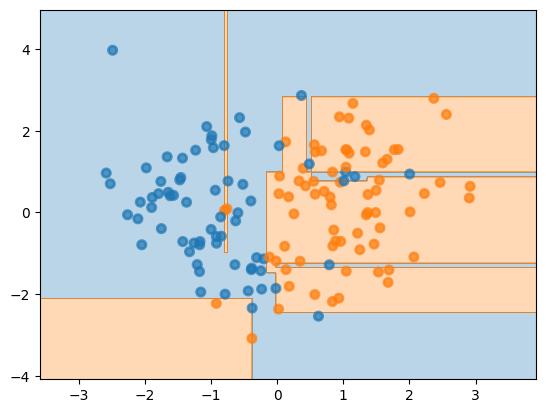

In [7]:
plot_surface(tree, X_train, y_train)

__Задание 2.__

Переберите несколько параметров для регуляризации (`max_depth`, `min_samples_leaf`) из предложенных. Для каждого набора гиперпараметров постройте разделяющую поверхность, выведите обучающую и тестовую ошибки. Используйте, если хотите, функцию ниже. Как изменение параметров влияет на поверхность? При каких параметрах на тесте достигается лучшее качество? А на трейне? (2б).

In [8]:
def plot_surface_axes(clf, X, y, ax, train_acc, test_acc):
    plot_step = 0.01
    palette = sns.color_palette(n_colors=len(np.unique(y)))
    cmap = ListedColormap(palette)
    X_values = X.to_numpy() if isinstance(X, pd.DataFrame) else np.asarray(X)
    x_min, x_max = X_values[:, 0].min() - 1, X_values[:, 0].max() + 1
    y_min, y_max = X_values[:, 1].min() - 1, X_values[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, plot_step),
                         np.arange(y_min, y_max, plot_step))
    plt.tight_layout(h_pad=0.5, w_pad=0.5, pad=2.5)

    mesh = np.c_[xx.ravel(), yy.ravel()]
    if isinstance(X, pd.DataFrame):
        mesh = pd.DataFrame(mesh, columns=X.columns)
    Z = clf.predict(mesh)
    Z = Z.reshape(xx.shape)
    cs = plt.contourf(xx, yy, Z, cmap=cmap, alpha=0.3)

    ax.scatter(X_values[:, 0], X_values[:, 1], c=y, cmap=cmap, alpha=.7,
    edgecolors=np.array(palette)[y], linewidths=2)
    
    ax.plot([], [], label = 'train_acc : %0.5f' % train_acc)
    ax.plot([], [], label = 'test_acc : %0.5f' % test_acc)
    
    plt.legend(loc = 'lower right', prop={'size': 20})

In [11]:
max_depth_set = [6, 7, 8, 9, 12]

min_samples_leaf_set = [3, 5, 7, 10]

X_train, X_test, y_train, y_test = train_test_split(X, y, 
                                                    test_size=0.2,
                                                    random_state = 42) 

max_depth = 6, min_samples_leaf = 3 , train accuracy: 0.943750, test accuracy: 0.800000
max_depth = 6, min_samples_leaf = 5 , train accuracy: 0.925000, test accuracy: 0.800000
max_depth = 6, min_samples_leaf = 7 , train accuracy: 0.912500, test accuracy: 0.800000
max_depth = 6, min_samples_leaf = 10 , train accuracy: 0.900000, test accuracy: 0.800000
max_depth = 7, min_samples_leaf = 3 , train accuracy: 0.943750, test accuracy: 0.800000
max_depth = 7, min_samples_leaf = 5 , train accuracy: 0.925000, test accuracy: 0.800000
max_depth = 7, min_samples_leaf = 7 , train accuracy: 0.912500, test accuracy: 0.800000
max_depth = 7, min_samples_leaf = 10 , train accuracy: 0.900000, test accuracy: 0.800000
max_depth = 8, min_samples_leaf = 3 , train accuracy: 0.943750, test accuracy: 0.800000
max_depth = 8, min_samples_leaf = 5 , train accuracy: 0.925000, test accuracy: 0.800000
max_depth = 8, min_samples_leaf = 7 , train accuracy: 0.912500, test accuracy: 0.800000
max_depth = 8, min_samples_lea

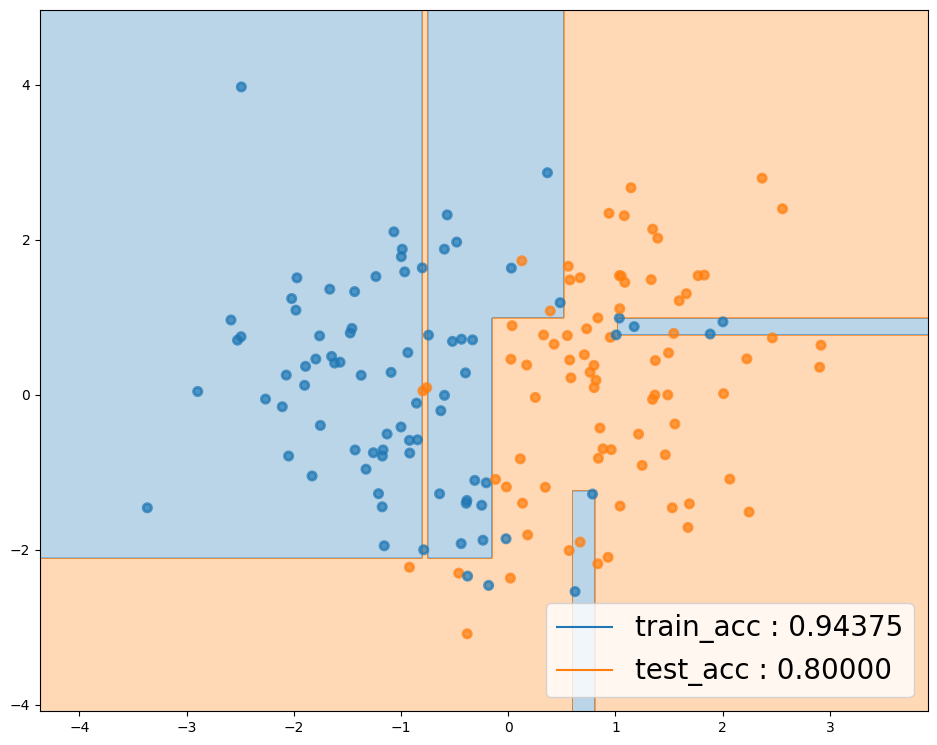

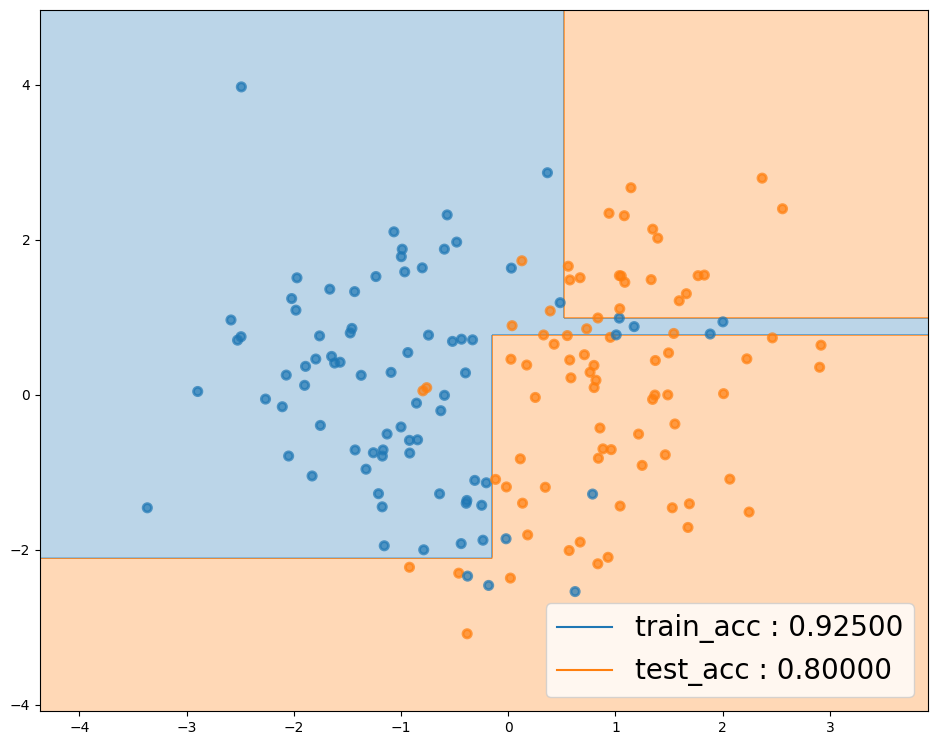

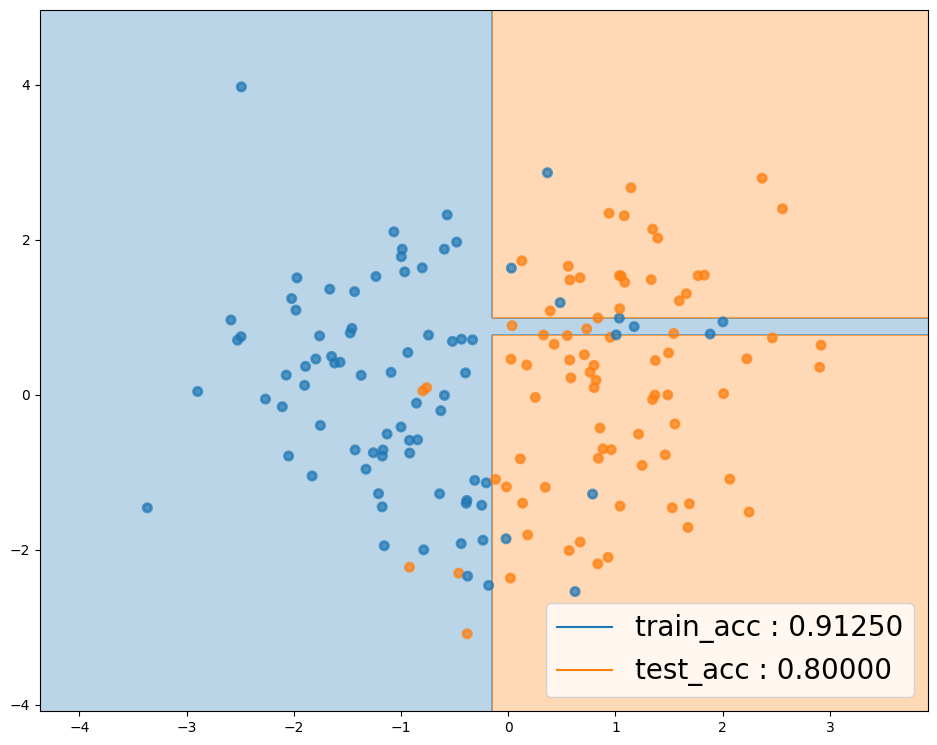

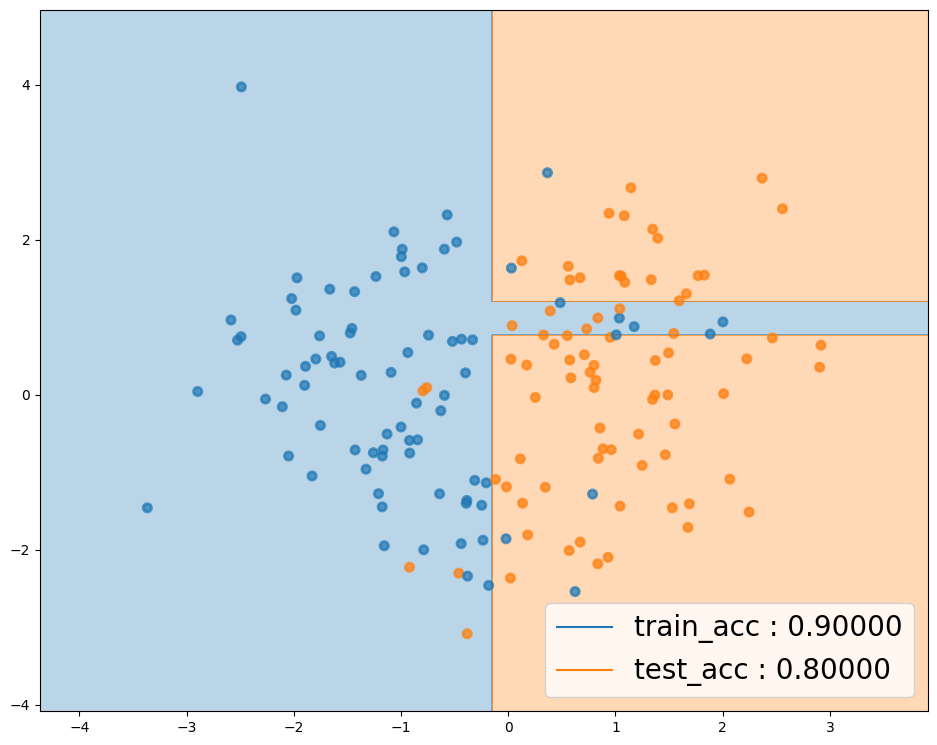

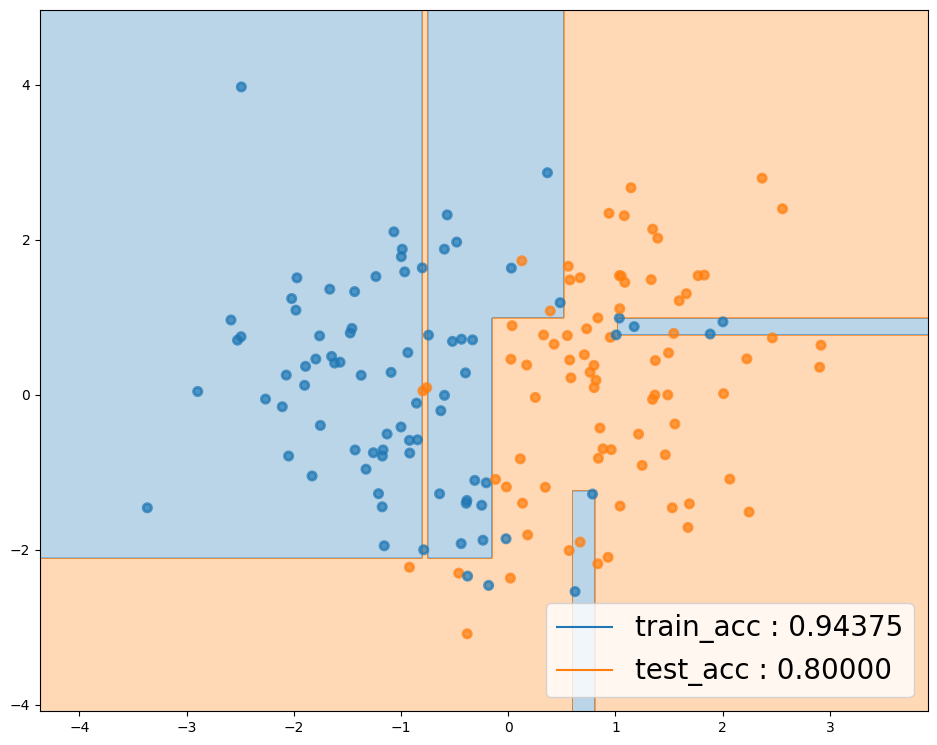

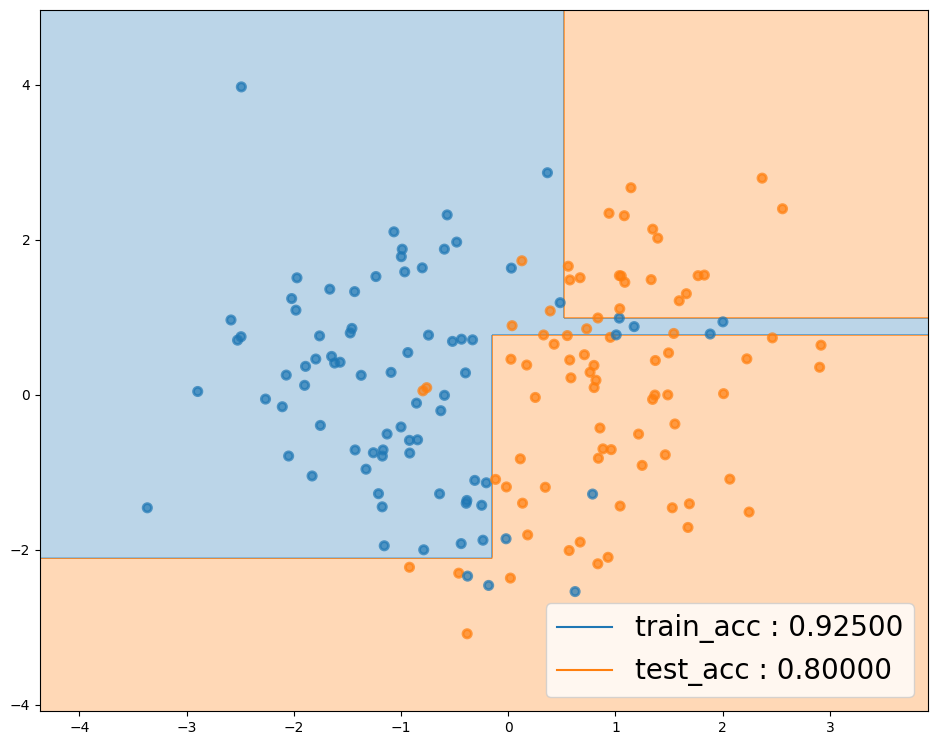

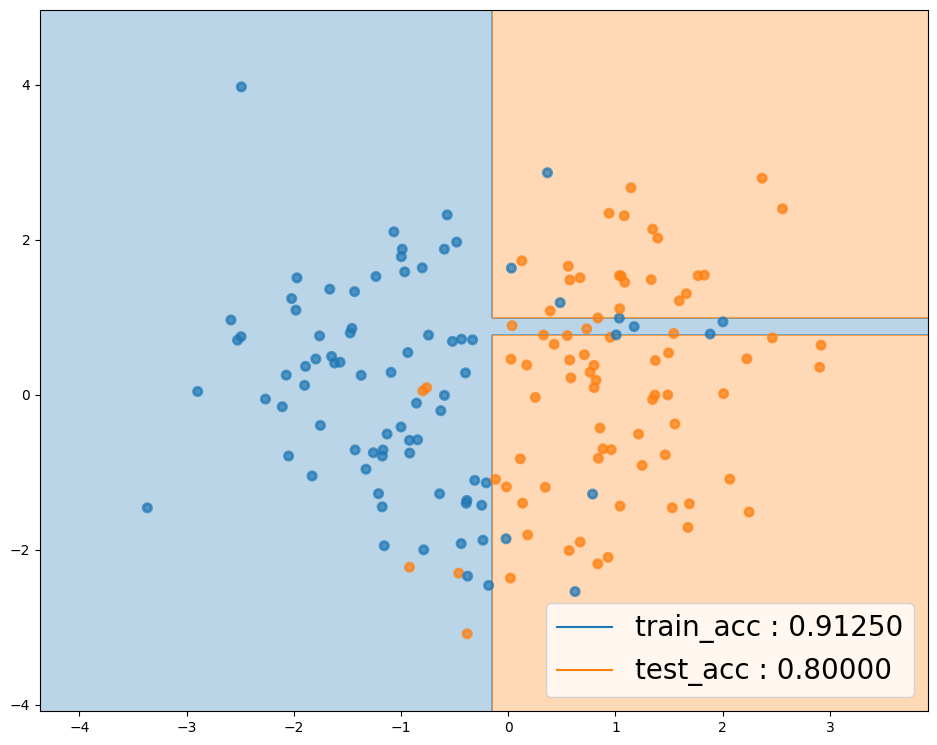

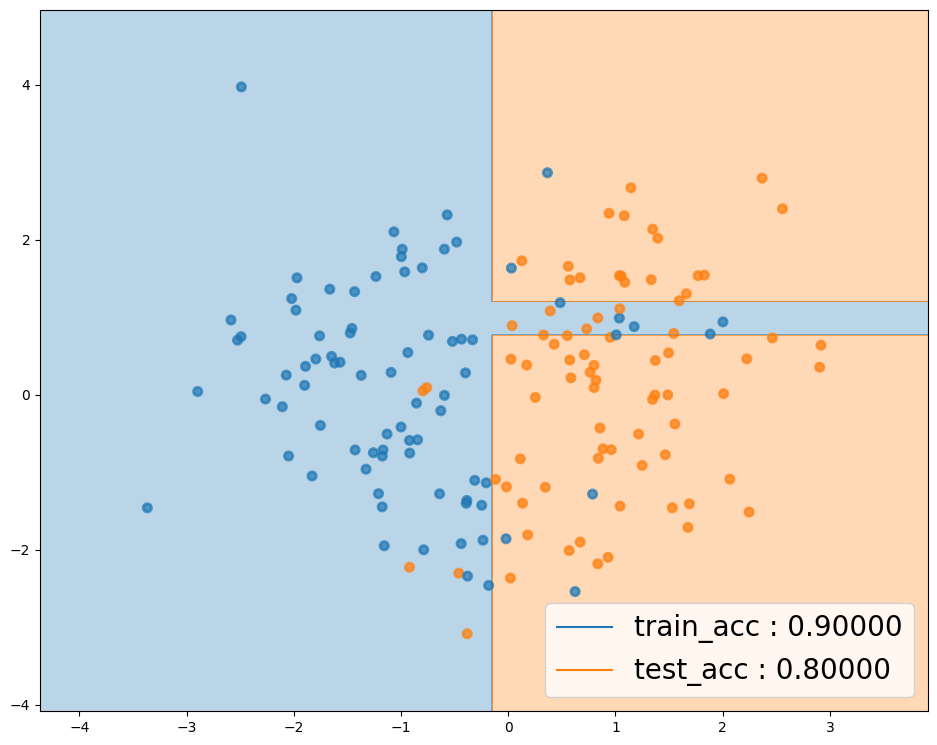

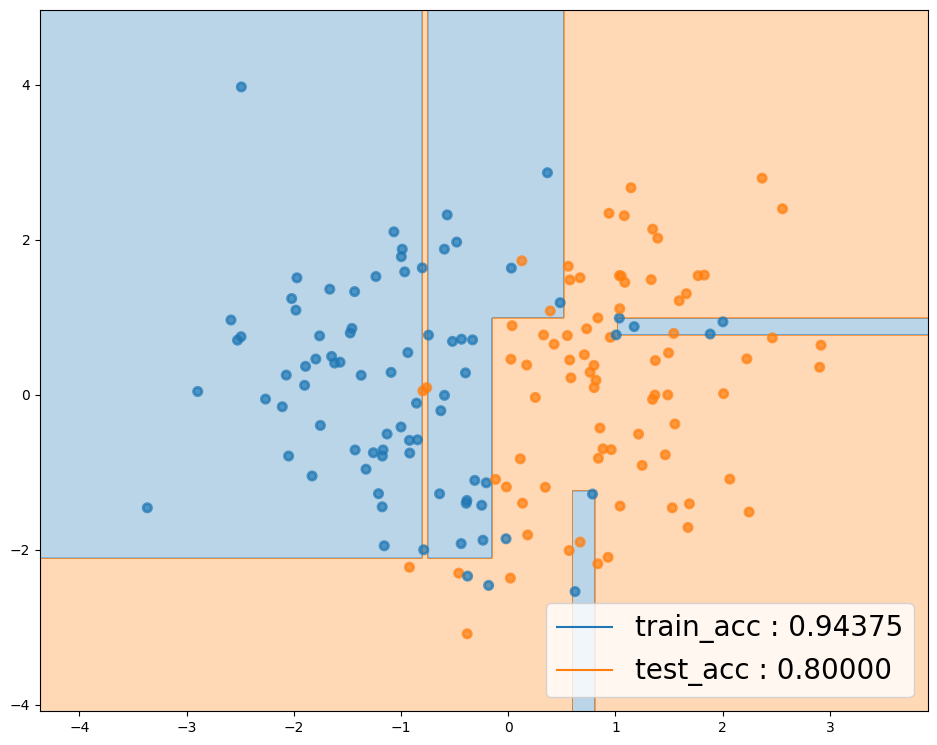

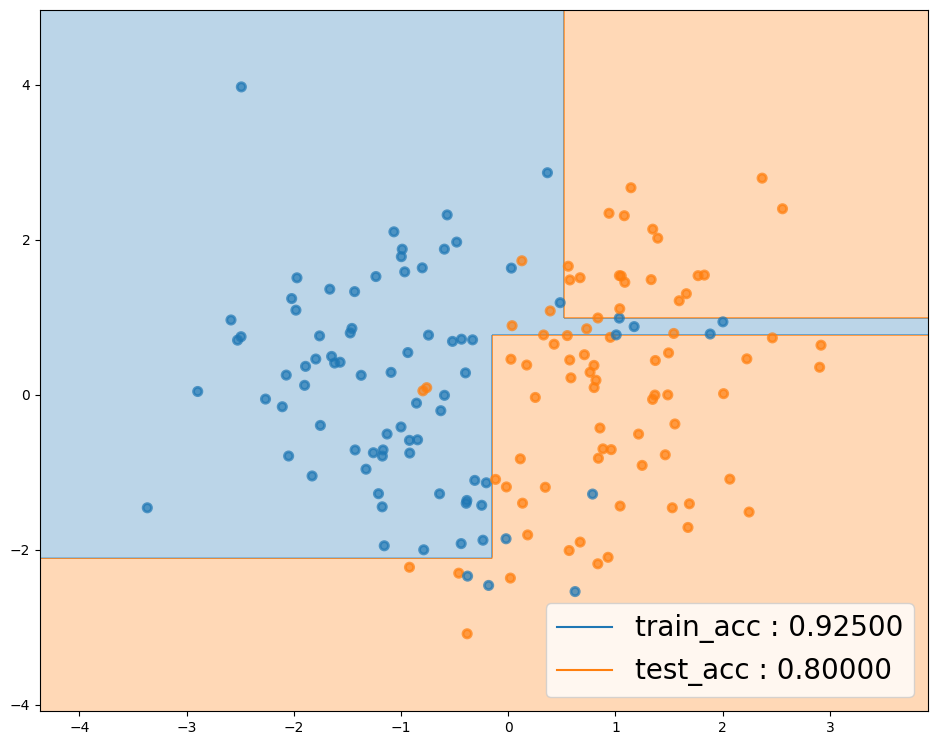

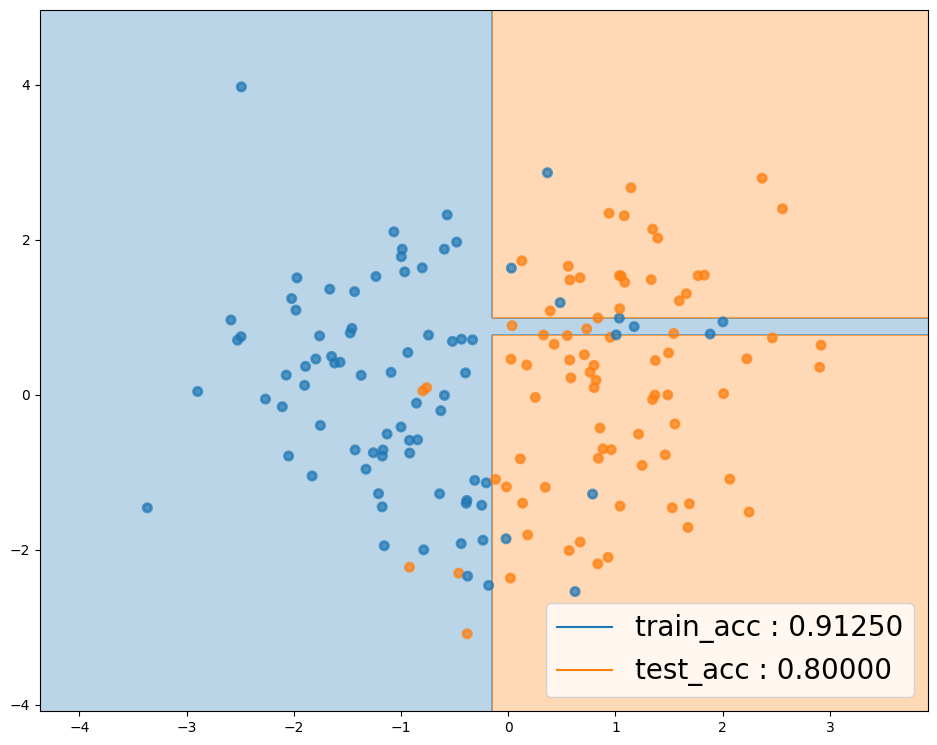

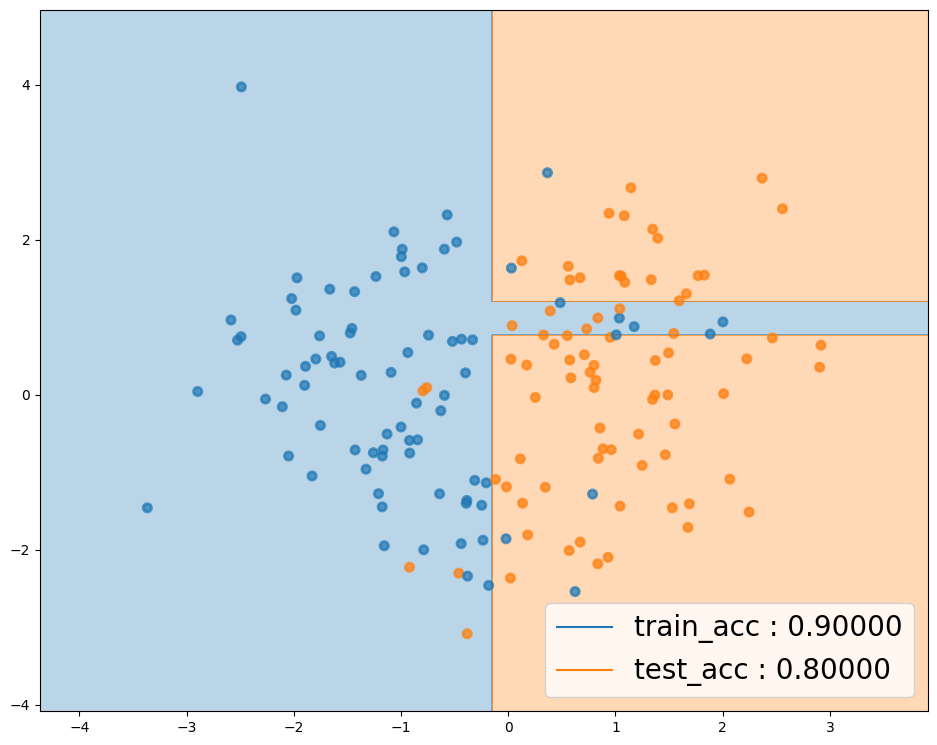

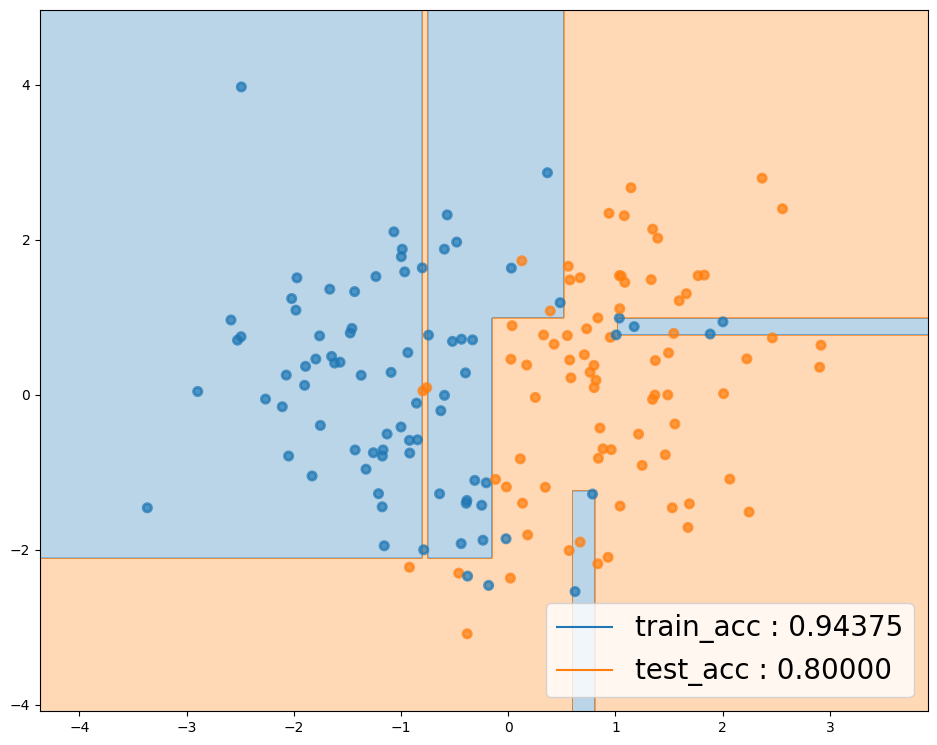

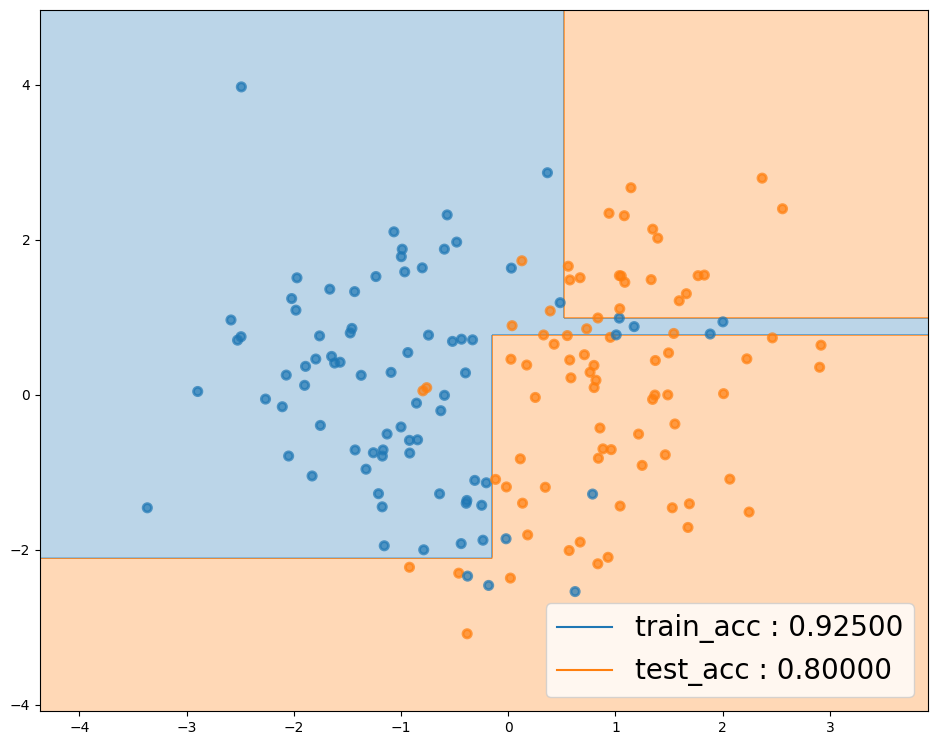

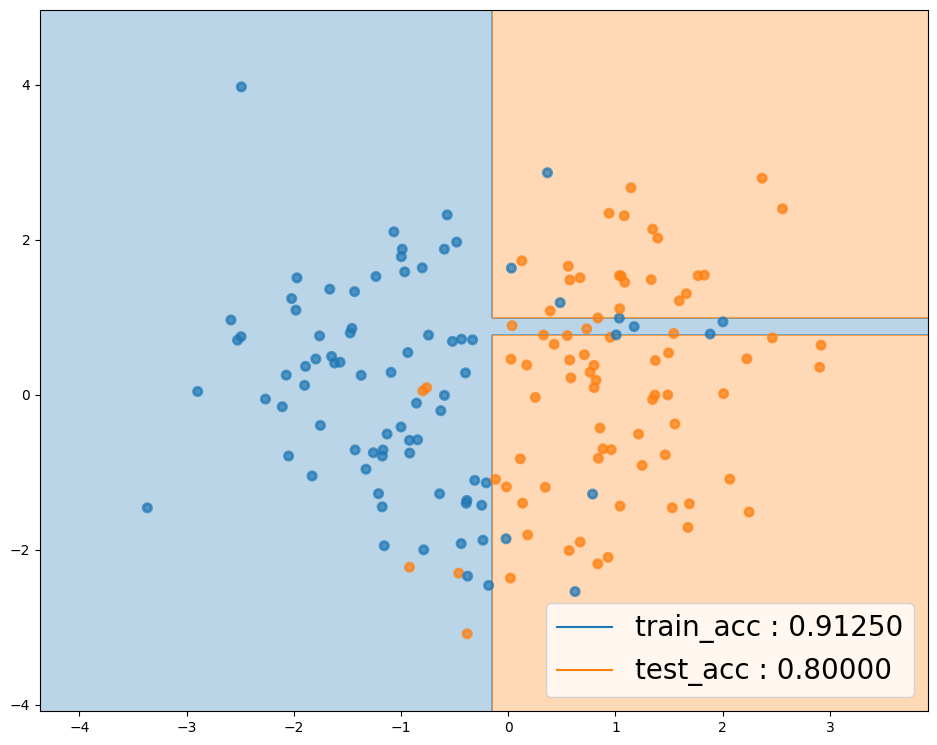

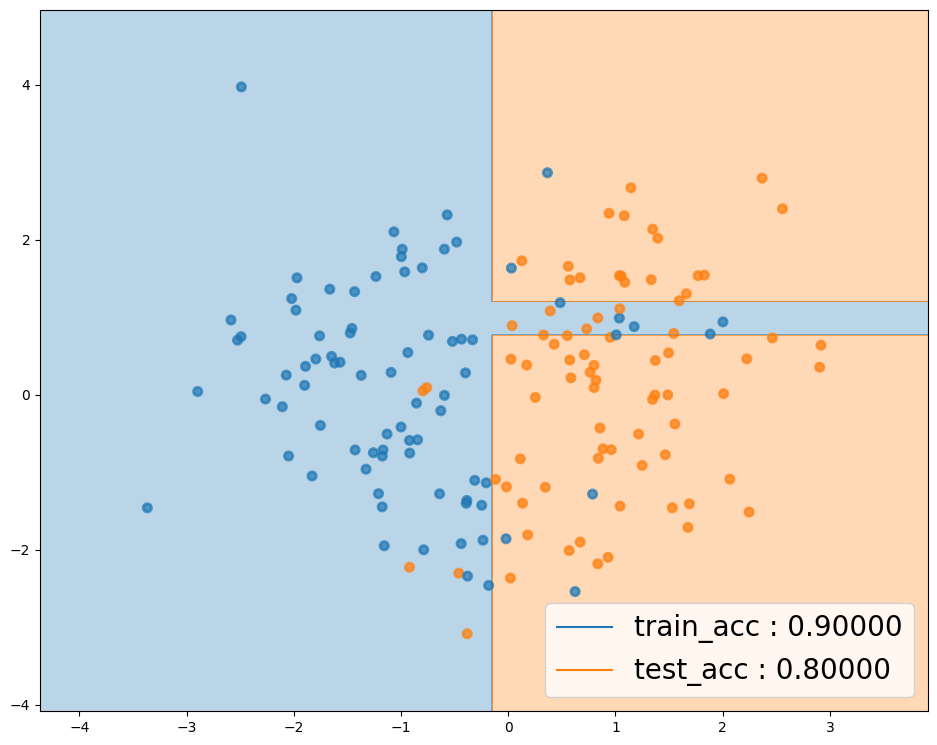

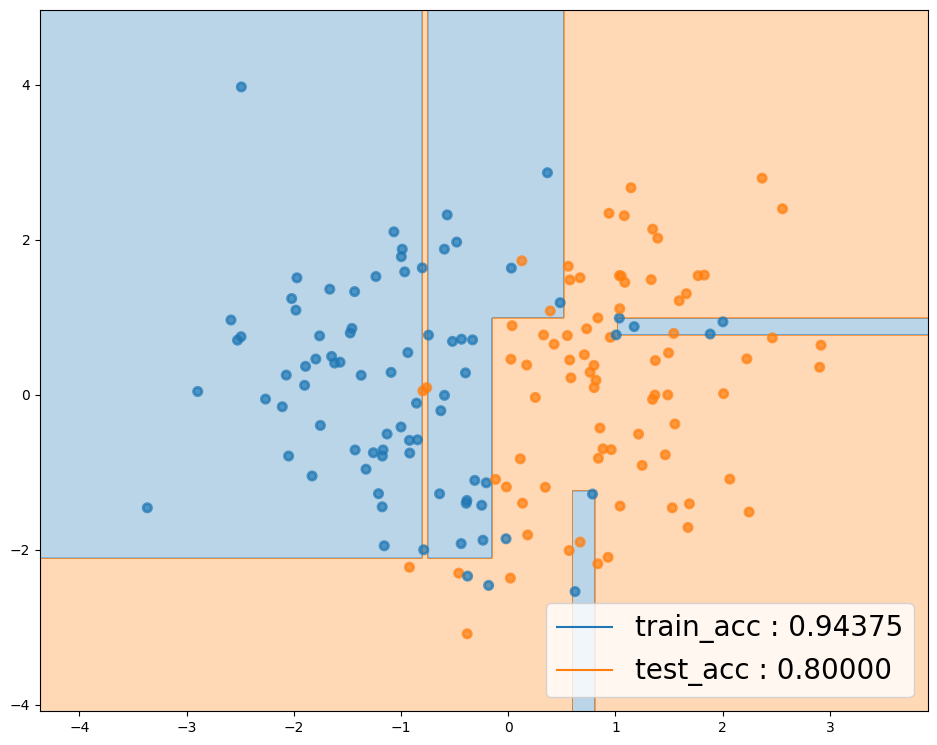

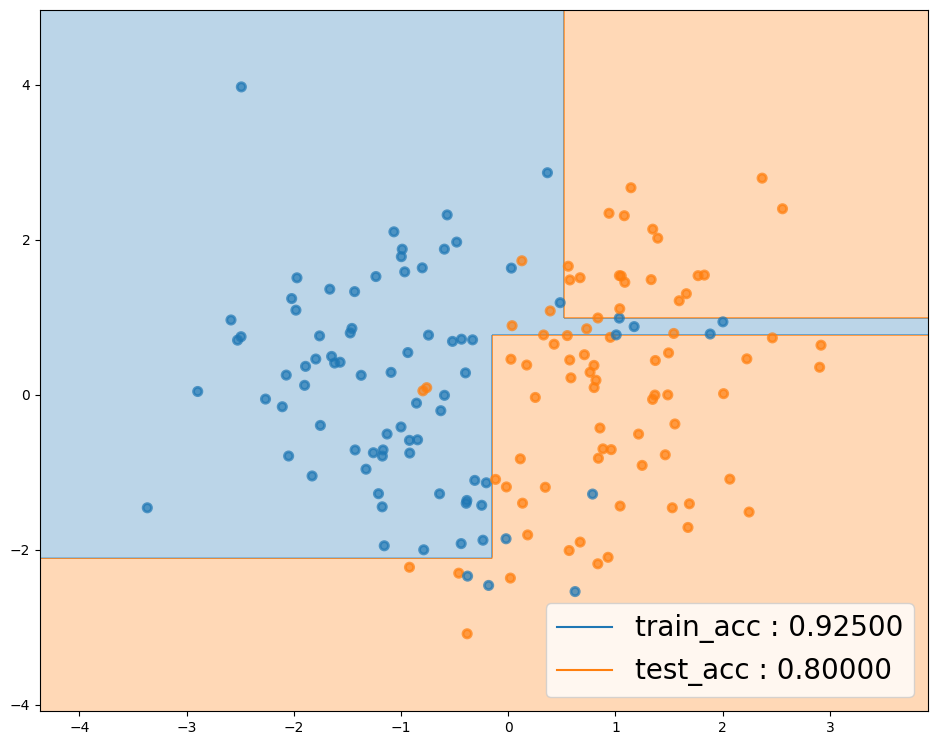

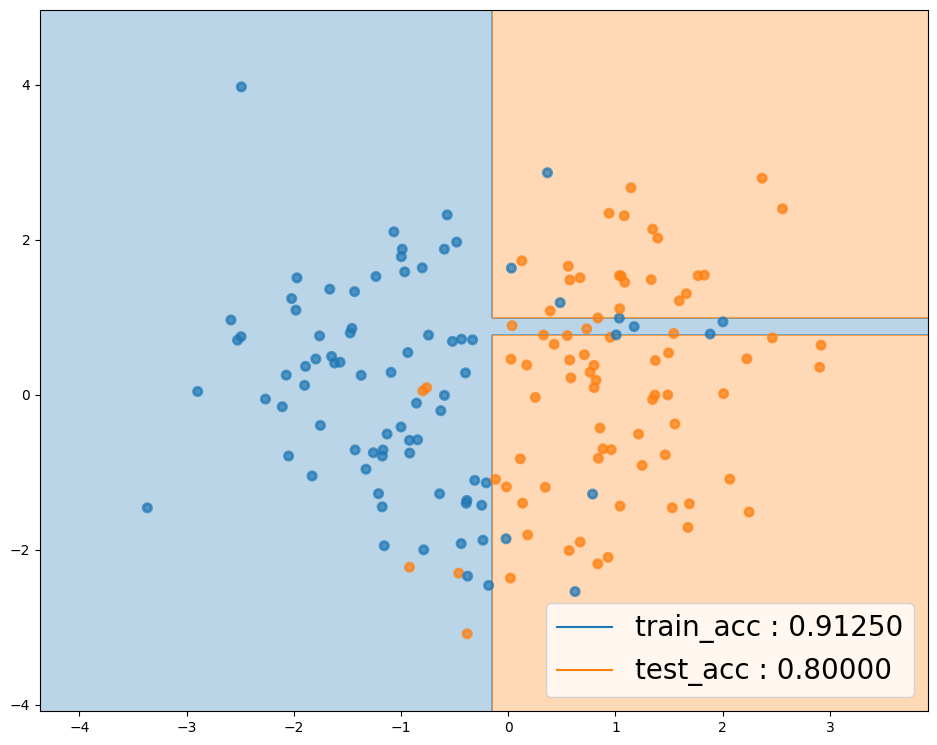

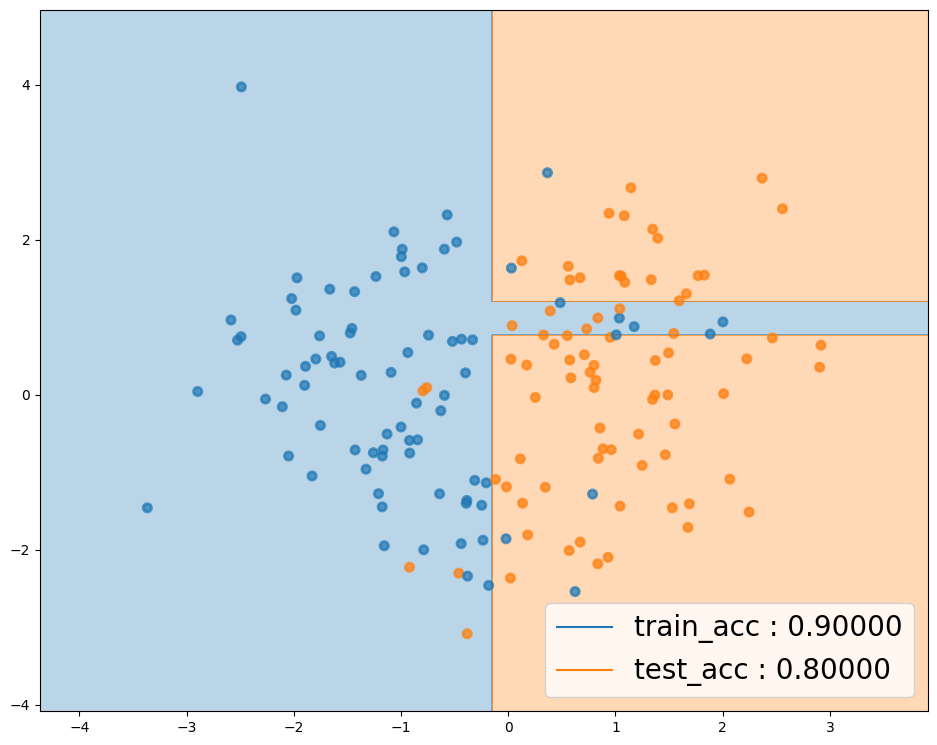

In [12]:
### Your code is here

best_params = {}
best_params['max_depth'] = 0
best_params['min_samples_leaf'] = 0
best_params['test_acc'] = 0
best_params['train_acc'] = 0
for max_depth in max_depth_set:
    for min_samples_leaf in min_samples_leaf_set:
        tree = DecisionTreeClassifier(max_depth = max_depth, min_samples_leaf = min_samples_leaf)
        tree.fit(X_train, y_train)
        tree_train_acc = accuracy_score(y_train, tree.predict(X_train))
        tree_test_acc = accuracy_score(y_test, tree.predict(X_test))
        print(f'max_depth = {max_depth}, min_samples_leaf = {min_samples_leaf} , train accuracy: {tree_train_acc:.6f}, test accuracy: {tree_test_acc:.6f}')
        if (tree_test_acc > best_params['test_acc']) & (tree_train_acc > best_params['train_acc']):
            best_params['max_depth'] = max_depth
            best_params['min_samples_leaf'] = min_samples_leaf
            best_params['test_acc'] = tree_test_acc
            best_params['train_acc'] = tree_train_acc
        elif (tree_test_acc == best_params['test_acc']) & (tree_train_acc == best_params['train_acc']):
            if best_params['max_depth']<max_depth & best_params['min_samples_leaf']<min_samples_leaf:
                best_params['max_depth'] = max_depth
                best_params['min_samples_leaf'] = min_samples_leaf
            
                
        fig, ax = plt.subplots(figsize=(10, 8))
        plot_surface_axes(tree, X_train, y_train, ax, tree_train_acc, tree_test_acc)

print(best_params)

__Задание 3.__

Добавим признак $2\cdot x_1 - x_2$, транформацию добавим как шаг пайплайна. С помощью данного класса (из практики/лекции) обучите дерево с максимальной глубиной=3, нарисуйте поверхность на трейне, посчитайте accuracy (2 б)

In [13]:
from sklearn.base import BaseEstimator, TransformerMixin

class CustomFunctionTransformer(BaseEstimator, TransformerMixin):
    
    def __init__(self, first_col, second_col, function):
        self.first_col = first_col
        self.second_col = second_col
        self.function = function
        print("Инициализировали класс!")
        
    def fit(self, X, y=None):
        print("Зафитили датасет!")
        return self
    
    def transform(self, X, y=None):
        
        X_ = X.copy()
        X_['new_feature'] = self.function(X_[self.first_col], X_[self.second_col])
        X_ = X_.drop([self.first_col, self.second_col], axis=1)
        
        print("Трансформировали датасет!")
        return X_

In [14]:
X_train = pd.DataFrame(X_train, columns=['x1', 'x2'])
X_test = pd.DataFrame(X_test, columns=['x1', 'x2'])

Инициализировали класс!
Зафитили датасет!
Трансформировали датасет!
Трансформировали датасет!
Трансформировали датасет!
train accuracy: 0.86, test accuracy: 0.75
Трансформировали датасет!


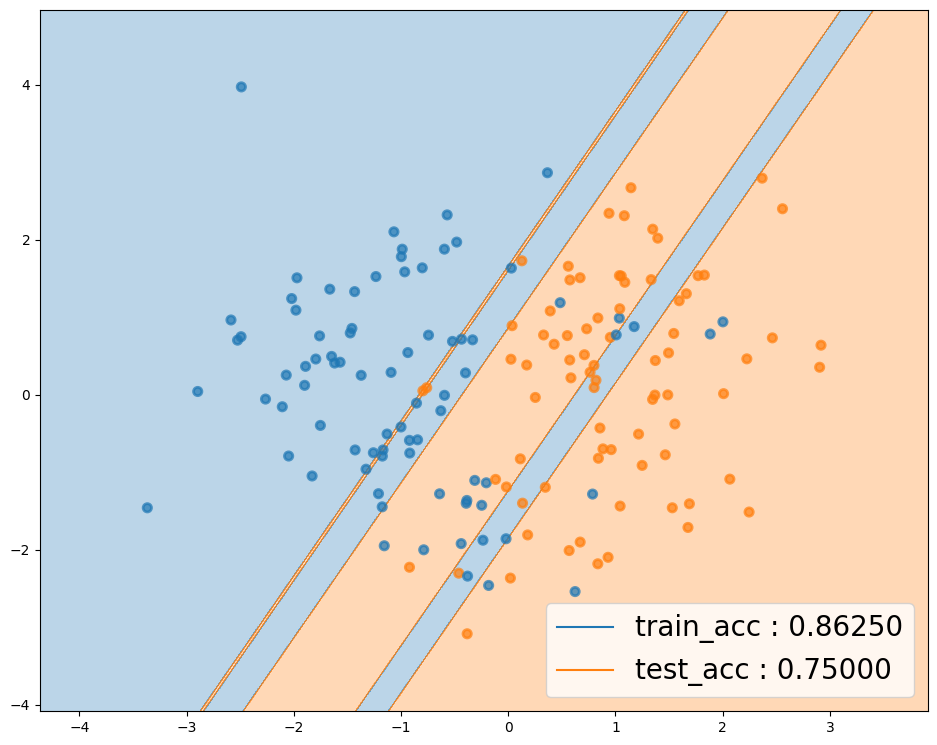

In [17]:
from sklearn.pipeline import Pipeline

### Your code is here

tree_custom = Pipeline([('custom', CustomFunctionTransformer('x1', 'x2', lambda x1, x2: 2 * x1 - x2)),
                        ('decision_tree', DecisionTreeClassifier(max_depth=3))])
tree_custom.fit(X_train, y_train)
tree_custom_train_acc = accuracy_score(y_train, tree_custom.predict(X_train))
tree_custom_test_acc = accuracy_score(y_test, tree_custom.predict(X_test))
print(f'train accuracy: {tree_custom_train_acc:.2f}, test accuracy: {tree_custom_test_acc:.2f}')

fig, ax = plt.subplots(figsize=(10, 8))
plot_surface_axes(tree_custom, X_train, y_train, ax, tree_custom_train_acc, tree_custom_test_acc)

